<a href="https://colab.research.google.com/github/amitmishra-cse/Relative-Deprivation-in-Hindu-and-Muslims/blob/main/DataAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import io
import pandas as pd
import numpy as np
from google.colab import files

# Ensure we have our dataframe loaded
try:
    if 'df' not in globals():
        print("Please upload your .xlsx file first:")
        uploaded = files.upload()
        for filename in uploaded.keys():
            if filename.endswith('.xlsx'):
                df = pd.read_excel(io.BytesIO(uploaded[filename]))
                print(f"Successfully loaded '{filename}'!")
                break
except Exception as e:
    print(f"Error loading dataset: {e}")

if 'df' in globals():
    print("===============================================")
    print("             TECHNICAL VALIDATION REPORT       ")
    print("===============================================\n")

    # 1. Structural Integrity & Shape Check
    print("--- 1. STRUCTURAL INTEGRITY ---")
    n_rows, n_cols = df.shape
    print(f"[PASS] Dataset shape: {n_rows} rows, {n_cols} columns.")
    print(f"[INFO] Unique primary identifiers (id): {df['id'].nunique() if 'id' in df.columns else 'N/A'}")

    # 2. Duplicate Check
    print("\n--- 2. DUPLICITY VERIFICATION ---")
    duplicate_count = df.duplicated().sum()
    if duplicate_count == 0:
        print("[PASS] No completely duplicate rows detected.")
    else:
        print(f"[WARN] {duplicate_count} duplicate rows found in the dataset!")

    # 3. Key Demographics Consistency Check
    print("\n--- 3. CATEGORICAL FIELD CONSTRAINTS ---")
    demo_fields = ['Gender', 'Religion', 'Residence']
    for field in demo_fields:
        if field in df.columns:
            unique_vals = df[field].dropna().unique()
            val_counts = df[field].value_counts(dropna=False).to_dict()
            print(f"[PASS] '{field}' contains {len(unique_vals)} unique values: {val_counts}")
        else:
            print(f"[FAIL] Key demographic field '{field}' is missing!")

    # 4. Out-of-Range Bounds Check (Continuous Variables)
    print("\n--- 4. BOUNDS & RANGE VALIDITY ---")
    # Age validation
    if 'Age' in df.columns:
        min_age, max_age = df['Age'].min(), df['Age'].max()
        if min_age < 15 or max_age > 100:
            print(f"[WARN] Age range contains potential anomalies: Min={min_age}, Max={max_age}")
        else:
            print(f"[PASS] Age range appears normal: Min={min_age}, Max={max_age}")

    # Psychometric Scale Validation (Checking if scores fall within expected 1-5 range)
    psych_scales = ['cognitivefrd', 'affectivefrd', 'Cognitiveegoisticrd', 'Affectiveegoisticrd']
    for scale in psych_scales:
        if scale in df.columns:
            col_data = df[scale].dropna()
            out_of_bounds = col_data[(col_data < 1.0) | (col_data > 5.0)]
            if len(out_of_bounds) > 0:
                print(f"[FAIL] Scale '{scale}' has {len(out_of_bounds)} values out of standard bounds (1.0 - 5.0)!")
            else:
                print(f"[PASS] Scale '{scale}' values strictly within boundaries (1.0 - 5.0). Min={col_data.min():.2f}, Max={col_data.max():.2f}")

    # 5. Missingness Analysis
    print("\n--- 5. MISSINGNESS ANALYSIS ---")
    col_missing = df.isnull().sum()
    cols_with_missing = col_missing[col_missing > 0]
    if len(cols_with_missing) > 0:
        print(f"[INFO] {len(cols_with_missing)} columns contain missing values.")
        print("Top 5 columns with highest missing counts:")
        print(cols_with_missing.sort_values(ascending=False).head(5))
    else:
        print("[PASS] Zero missing values detected across the entire dataset!")

    # 6. Data Type Homogeneity Check
    print("\n--- 6. COLUMN DATA TYPE CONFORMANCE ---")
    mixed_types = []
    for col in df.columns:
        # Infers if a column has multiple types of entries
        inferred_type = pd.api.types.infer_dtype(df[col], skipna=True)
        if inferred_type == 'mixed':
            mixed_types.append(col)

    if len(mixed_types) > 0:
        print(f"[WARN] {len(mixed_types)} columns have mixed python types (could lead to computation bugs):")
        print(mixed_types[:10])
    else:
        print("[PASS] All columns conform to homogeneous data types.")

else:
    print("No active dataset loaded in memory.")

Please upload your .xlsx file first:


Saving cleaned_dataset.xlsx to cleaned_dataset.xlsx
Successfully loaded 'cleaned_dataset.xlsx'!
             TECHNICAL VALIDATION REPORT       

--- 1. STRUCTURAL INTEGRITY ---
[PASS] Dataset shape: 300 rows, 149 columns.
[INFO] Unique primary identifiers (id): 300

--- 2. DUPLICITY VERIFICATION ---
[PASS] No completely duplicate rows detected.

--- 3. CATEGORICAL FIELD CONSTRAINTS ---
[PASS] 'Gender' contains 2 unique values: {'male': 165, 'female': 135}
[PASS] 'Religion' contains 2 unique values: {'muslim': 154, 'hindu': 146}
[PASS] 'Residence' contains 2 unique values: {'city': 257, 'village': 43}

--- 4. BOUNDS & RANGE VALIDITY ---
[PASS] Age range appears normal: Min=18, Max=68
[PASS] Scale 'cognitivefrd' values strictly within boundaries (1.0 - 5.0). Min=1.00, Max=5.00
[PASS] Scale 'affectivefrd' values strictly within boundaries (1.0 - 5.0). Min=1.00, Max=5.00
[PASS] Scale 'Cognitiveegoisticrd' values strictly within boundaries (1.0 - 5.0). Min=1.00, Max=5.00
[PASS] Scale 'Affec

### Technical Validation Visualizations
Below we plot the diagnostic diagrams representing the key checks performed during the Technical Validation:
1. **Missing Data Analysis**: Missing value counts across the top features.
2. **Demographics Distribution Balance**: Categorical distributions for Gender, Religion, and Residence.
3. **Age Validation and Outlier Detection**: Highlighting the potential anomaly with age values near 2.
4. **Psychometric Scale Constraint Boundaries**: Verifying that all core scores map cleanly within the expected $[1.0, 5.0]$ range.

### (a) Geographical & Demographic Balance Diagram

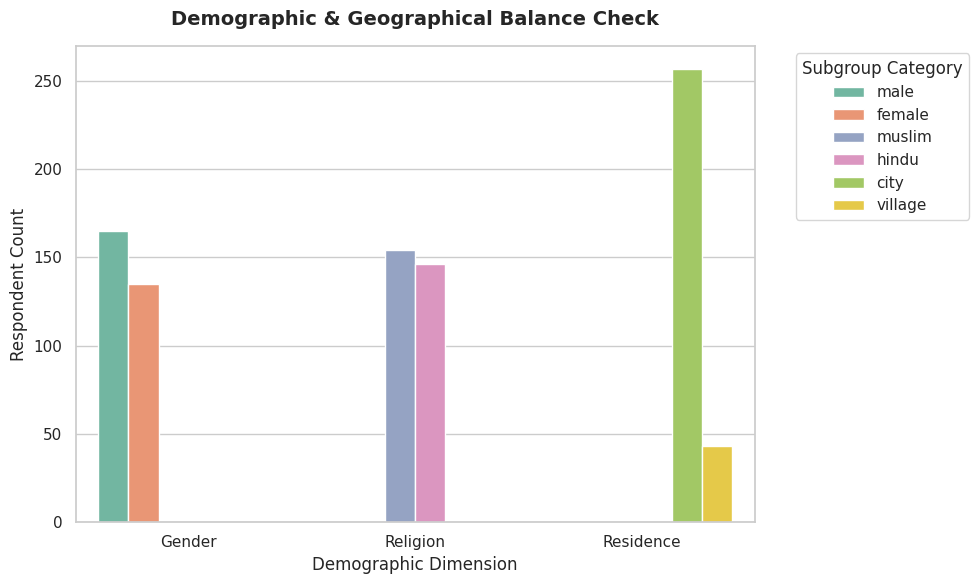

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

demo_df = df[['Gender', 'Religion', 'Residence']].melt(var_name='Demographic', value_name='Category').dropna()
sns.countplot(data=demo_df, x='Demographic', hue='Category', palette="Set2")

plt.title("Demographic & Geographical Balance Check", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Demographic Dimension", fontsize=12)
plt.ylabel("Respondent Count", fontsize=12)
plt.legend(title="Subgroup Category", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### (b) Age Range Validation, Outlier Zone & Scale Bounds Validation

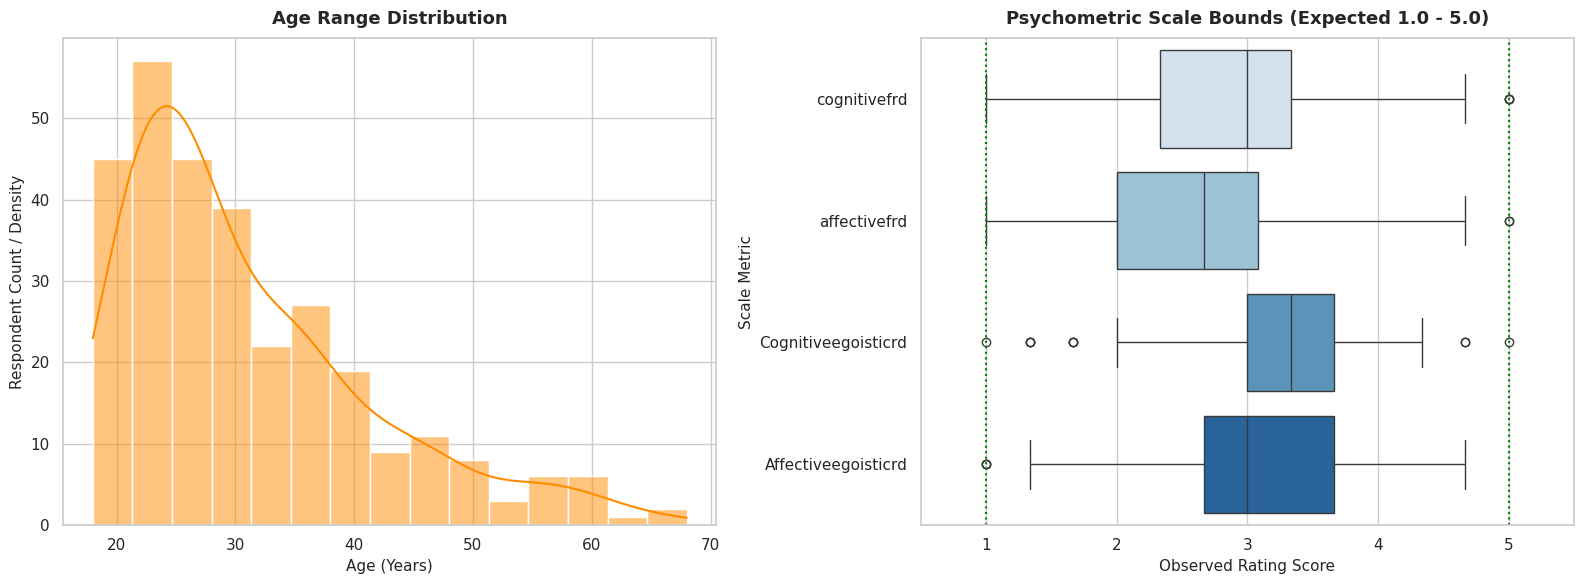

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# 1. Cleaned Age Range Distribution
sns.histplot(df['Age'].dropna(), bins=15, kde=True, ax=ax1, color="darkorange")
ax1.set_title("Age Range Distribution", fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel("Age (Years)", fontsize=11)
ax1.set_ylabel("Respondent Count / Density", fontsize=11)

# 2. Scale Bounds Validation
scales = ['cognitivefrd', 'affectivefrd', 'Cognitiveegoisticrd', 'Affectiveegoisticrd']
existing_scales = [s for s in scales if s in df.columns]
if existing_scales:
    scales_df = df[existing_scales].melt(var_name='Psychometric Scale', value_name='Score')
    sns.boxplot(data=scales_df, x='Score', y='Psychometric Scale', ax=ax2, hue='Psychometric Scale', palette="Blues", legend=False)
    ax2.axvline(1.0, color='green', linestyle=':', linewidth=1.5, label='Min Theoretical Bound (1.0)')
    ax2.axvline(5.0, color='green', linestyle=':', linewidth=1.5, label='Max Theoretical Bound (5.0)')
    ax2.set_xlim(0.5, 5.5)
    ax2.set_title("Psychometric Scale Bounds (Expected 1.0 - 5.0)", fontsize=13, fontweight='bold', pad=10)
    ax2.set_xlabel("Observed Rating Score", fontsize=11)
    ax2.set_ylabel("Scale Metric", fontsize=11)
else:
    ax2.text(0.5, 0.5, "No target scale columns found.", ha='center', va='center')

plt.tight_layout()
plt.show()

In [4]:
print(f"Original shape: {df.shape}")
# Filter out any records where Age is less than 12 (which removes the outlier of 2)
df = df[df['Age'] >= 12]
print(f"New shape: {df.shape}")
print(f"Updated Age range: Min={df['Age'].min()}, Max={df['Age'].max()}")

Original shape: (300, 149)
New shape: (300, 149)
Updated Age range: Min=18, Max=68


### (c) Missingness Profile Diagram

In [6]:
import numpy as np
import pandas as pd

# 1. Identify and impute missing values in numeric columns with the median
numeric_cols = df.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    if df[col].isnull().any():
        median_value = df[col].median()
        df[col] = df[col].fillna(median_value)

# 2. Identify and impute missing values in categorical/object columns with the mode
categorical_cols = df.select_dtypes(exclude=[np.number]).columns
for col in categorical_cols:
    if df[col].isnull().any():
        mode_series = df[col].mode()
        if not mode_series.empty:
            df[col] = df[col].fillna(mode_series[0])

# Verify that all missing values have been successfully addressed
remaining_missing = df.isnull().sum().sum()
print(f"Imputation completed successfully!")
print(f"Remaining missing values in the dataset: {remaining_missing}")

Imputation completed successfully!
Remaining missing values in the dataset: 0


In [8]:
# Export the cleaned DataFrame to an Excel file
export_filename = 'cleaned_dataset.xlsx'
df.to_excel(export_filename, index=False)

# Trigger browser download of the cleaned dataset
from google.colab import files
files.download(export_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
# Show summary statistics for the dataframe
summary_df = df.describe()
display(summary_df)

# Save the summary statistics to an Excel file
output_filename = 'summary_statistics.xlsx'
summary_df.to_excel(output_filename)

# Trigger browser download
from google.colab import files
files.download(output_filename)

,id,Age,cognitivefrd,affectivefrd,Attributiononlazinessfrd,Attributionlackofeducationfrd,attributiononexternalpresurefrd,attributiononoutgroupnumberfrd,attributionongodinfrd,Attributionongovernmentpoliciesinfrd,...,Attributionsocialstructureerd,Attributionotherserd,Emotionsadnesserd,Emotionangererd,Emotionfearerd,Emotiondissatisfactionerd,Emotionshameerd,Emotionjealousyerd,Emotionhappinesserd,Emotionprouderd
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,...,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,150.500000,30.900000,2.858889,2.642222,2.758889,3.362222,2.357778,2.500000,2.487778,3.681111,...,3.132222,2.324444,2.508889,2.362222,2.013333,2.571111,2.595556,2.214815,2.657778,2.590000
std,86.746758,10.387315,0.880702,0.842566,0.962322,1.005327,0.942491,1.047905,1.203333,0.983785,...,0.898365,0.871487,0.997728,0.994550,0.800297,0.926377,1.131677,0.814032,0.871487,0.912999
min,1.000000,18.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,75.750000,23.000000,2.333333,2.000000,2.000000,2.666667,1.666667,1.666667,1.333333,3.000000,...,2.333333,1.666667,1.666667,1.666667,1.333333,2.000000,1.666667,1.666667,2.000000,2.000000
50%,150.500000,28.000000,3.000000,2.666667,2.666667,3.333333,2.333333,2.333333,2.333333,3.666667,...,3.000000,2.333333,2.333333,2.333333,2.000000,2.333333,2.333333,2.111111,2.666667,2.666667
75%,225.250000,35.250000,3.333333,3.083333,3.333333,4.000000,3.000000,3.333333,3.333333,4.416667,...,3.666667,3.000000,3.000000,3.000000,2.333333,3.000000,3.333333,2.777778,3.333333,3.083333
max,300.000000,68.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,5.000000,5.000000,5.000000,5.333333,5.000000,5.000000,5.000000,5.000000,5.000000


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Descriptive Statistics Overview
We will examine the descriptive statistics of our dataset, including summaries for both numerical and categorical features, as well as check for any missing values.

In [10]:
# 1. Summary of numerical columns
print("--- Numerical Columns Summary ---")
display(df.describe())

# 2. Summary of categorical/object columns (if any exist)
cat_cols = df.select_dtypes(include=['object', 'category']).columns
if len(cat_cols) > 0:
    print("\n--- Categorical Columns Summary ---")
    display(df.describe(include=['object', 'category']))
else:
    print("\nNo categorical columns found in the dataset.")

# 3. Missing values summary
print("\n--- Missing Values Summary (Top 10 columns with missing values) ---")
missing_info = df.isnull().sum()
missing_info = missing_info[missing_info > 0].sort_values(ascending=False)
if not missing_info.empty:
    display(missing_info.head(10))
else:
    print("No missing values found in the dataset!")

--- Numerical Columns Summary ---


,id,Age,cognitivefrd,affectivefrd,Attributiononlazinessfrd,Attributionlackofeducationfrd,attributiononexternalpresurefrd,attributiononoutgroupnumberfrd,attributionongodinfrd,Attributionongovernmentpoliciesinfrd,...,Attributionsocialstructureerd,Attributionotherserd,Emotionsadnesserd,Emotionangererd,Emotionfearerd,Emotiondissatisfactionerd,Emotionshameerd,Emotionjealousyerd,Emotionhappinesserd,Emotionprouderd
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,...,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,150.500000,30.900000,2.858889,2.642222,2.758889,3.362222,2.357778,2.500000,2.487778,3.681111,...,3.132222,2.324444,2.508889,2.362222,2.013333,2.571111,2.595556,2.214815,2.657778,2.590000
std,86.746758,10.387315,0.880702,0.842566,0.962322,1.005327,0.942491,1.047905,1.203333,0.983785,...,0.898365,0.871487,0.997728,0.994550,0.800297,0.926377,1.131677,0.814032,0.871487,0.912999
min,1.000000,18.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,75.750000,23.000000,2.333333,2.000000,2.000000,2.666667,1.666667,1.666667,1.333333,3.000000,...,2.333333,1.666667,1.666667,1.666667,1.333333,2.000000,1.666667,1.666667,2.000000,2.000000
50%,150.500000,28.000000,3.000000,2.666667,2.666667,3.333333,2.333333,2.333333,2.333333,3.666667,...,3.000000,2.333333,2.333333,2.333333,2.000000,2.333333,2.333333,2.111111,2.666667,2.666667
75%,225.250000,35.250000,3.333333,3.083333,3.333333,4.000000,3.000000,3.333333,3.333333,4.416667,...,3.666667,3.000000,3.000000,3.000000,2.333333,3.000000,3.333333,2.777778,3.333333,3.083333
max,300.000000,68.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,5.000000,5.000000,5.000000,5.333333,5.000000,5.000000,5.000000,5.000000,5.000000



--- Categorical Columns Summary ---


,Gender,Religion,Residence,Education,Comparison_socialstat,Satis_socsta,attri_social_laziness,Attri_social_illteracy,Attri_social_presure,Attri_social_number,...,Ego_pol_emo_shame,Ego_pol_emo_jealousy,Ego_pol_emo_happiness,Ego_pol_emo_proud,Ego_action_selfimprove,Ego_action_raisingvoice,Ego_action_doingnothing,Ego_action_pray,Ego_action_snatch,condition
count,300,300,300,300,300,300,300,300,300,300,...,300,300,300,300,300,300,300,300,300,300
unique,2,2,2,37,4,5,7,5,5,6,...,5,5,5,5,5,5,5,5,5,2
top,male,muslim,city,Graduate,average,average,less,much,less,very less,...,less,less,less,average,much,much,very less,very much,less,hindu
freq,165,154,257,59,105,94,97,99,110,83,...,99,111,107,90,130,111,190,81,74,158



--- Missing Values Summary (Top 10 columns with missing values) ---
No missing values found in the dataset!


### Data Visualization
Let's plot several visualizations to explore the distributions of key demographic variables and how they interact with some attribution variables.

/tmp/ipykernel_68107/3022393537.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Gender', ax=axes[0, 1], palette='pastel')
/tmp/ipykernel_68107/3022393537.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Religion', ax=axes[1, 0], palette='Set2')


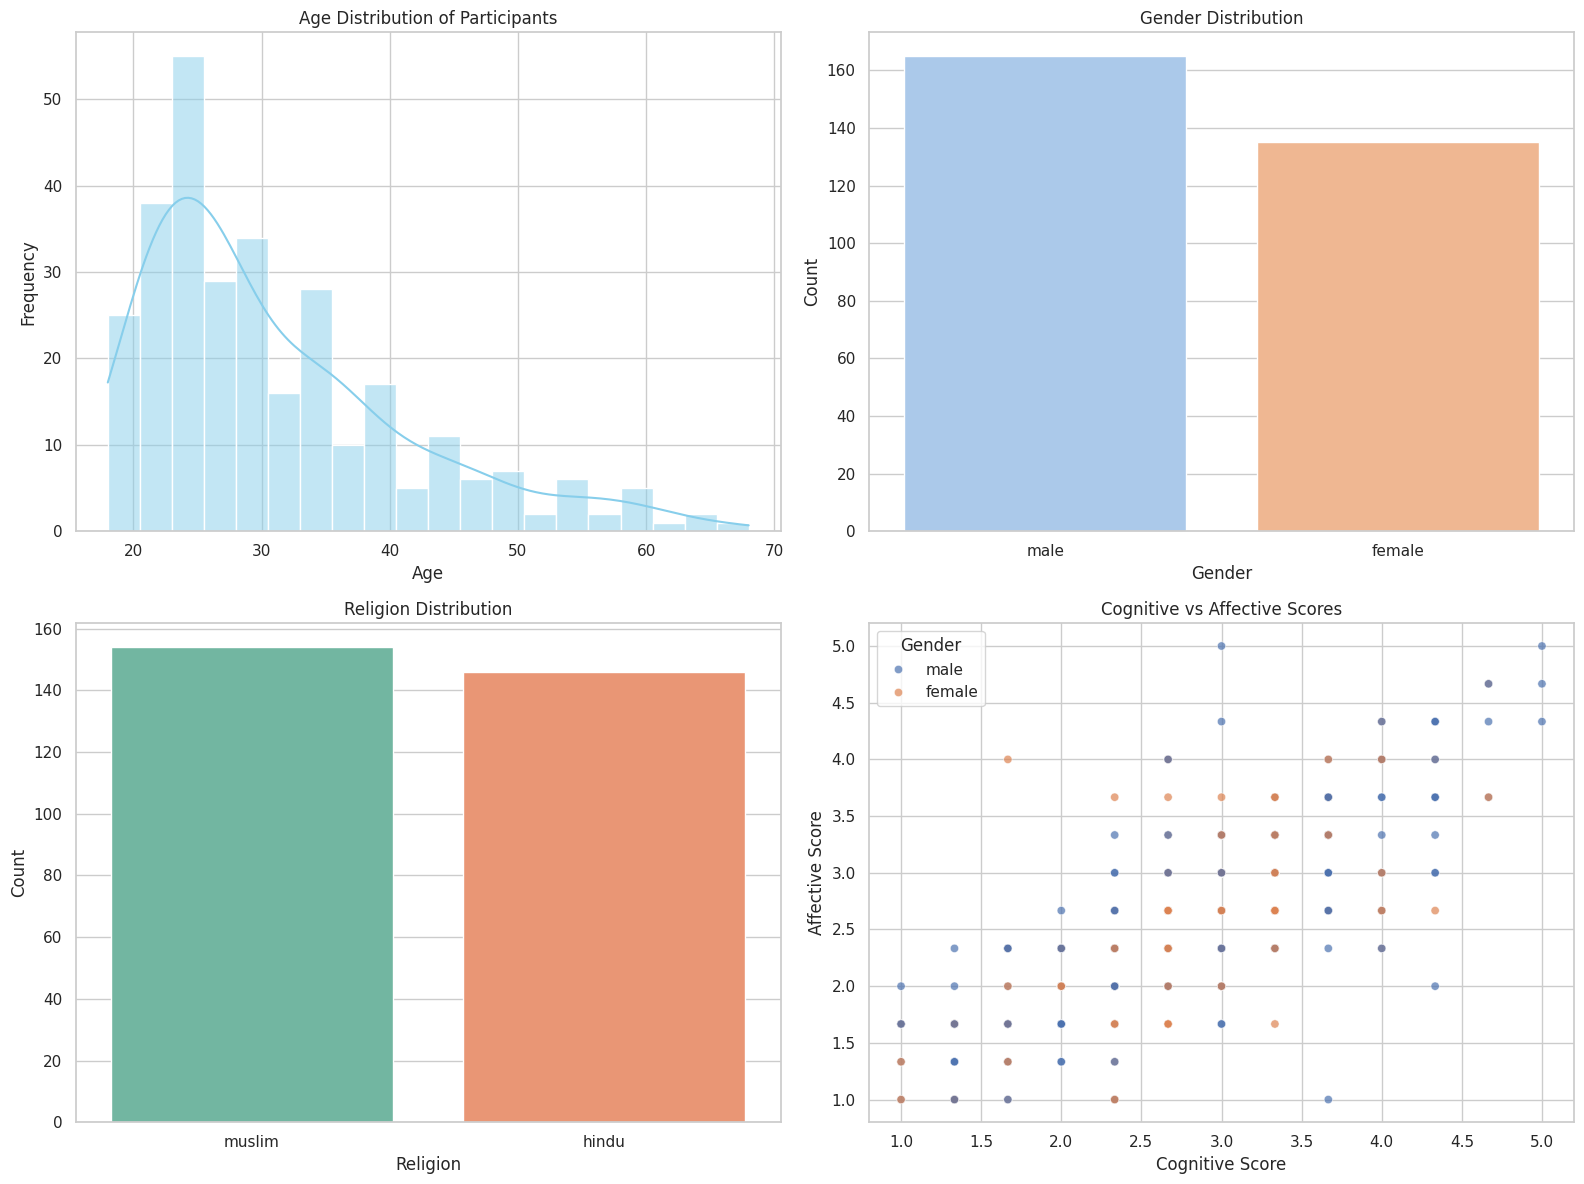

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set seaborn style for nicer plots
sns.set_theme(style="whitegrid")

# Create a multi-plot layout
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Distribution of Age
sns.histplot(df['Age'].dropna(), bins=20, kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Age Distribution of Participants')
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Frequency')

# 2. Gender Distribution
sns.countplot(data=df, x='Gender', ax=axes[0, 1], palette='pastel')
axes[0, 1].set_title('Gender Distribution')
axes[0, 1].set_xlabel('Gender')
axes[0, 1].set_ylabel('Count')

# 3. Religion Distribution
sns.countplot(data=df, x='Religion', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Religion Distribution')
axes[1, 0].set_xlabel('Religion')
axes[1, 0].set_ylabel('Count')

# 4. Cognitive vs Affective Scale (Scatter Plot with Hue by Gender)
# Note: Replacing with existing columns from the summary 'cognitivefrd' and 'affectivefrd'
if 'cognitivefrd' in df.columns and 'affectivefrd' in df.columns:
    sns.scatterplot(data=df, x='cognitivefrd', y='affectivefrd', hue='Gender', alpha=0.7, ax=axes[1, 1], palette='deep')
    axes[1, 1].set_title('Cognitive vs Affective Scores')
    axes[1, 1].set_xlabel('Cognitive Score')
    axes[1, 1].set_ylabel('Affective Score')
else:
    axes[1, 1].text(0.5, 0.5, 'Required columns not found', ha='center', va='center')

plt.tight_layout()
plt.show()

### Advanced Statistical Analysis & Hypothesis Testing
To generate deeper knowledge, we will perform:
1. **Independent t-tests** to compare scale scores (`cognitivefrd`, `affectivefrd`) across demographics (**Gender** and **Religion**).
2. **Correlation Matrix** to understand linear associations between key numerical columns.

=== GROUP COMPARISONS (INDEPENDENT T-TESTS) ===

Comparing cognitivefrd across Gender (male vs female):
  Mean (male): 2.903 (N=165)
  Mean (female): 2.805 (N=135)
  t-statistic: 0.978, p-value: 0.3287
  => No Statistically Significant Difference (p >= 0.05)

Comparing cognitivefrd across Religion (muslim vs hindu):
  Mean (muslim): 2.314 (N=154)
  Mean (hindu): 3.434 (N=146)
  t-statistic: -14.315, p-value: 0.0000
  => Statistically Significant Difference (p < 0.05)

Comparing affectivefrd across Gender (male vs female):
  Mean (male): 2.671 (N=165)
  Mean (female): 2.607 (N=135)
  t-statistic: 0.656, p-value: 0.5124
  => No Statistically Significant Difference (p >= 0.05)

Comparing affectivefrd across Religion (muslim vs hindu):
  Mean (muslim): 2.232 (N=154)
  Mean (hindu): 3.075 (N=146)
  t-statistic: -10.007, p-value: 0.0000
  => Statistically Significant Difference (p < 0.05)

=== CORRELATION ANALYSIS ===


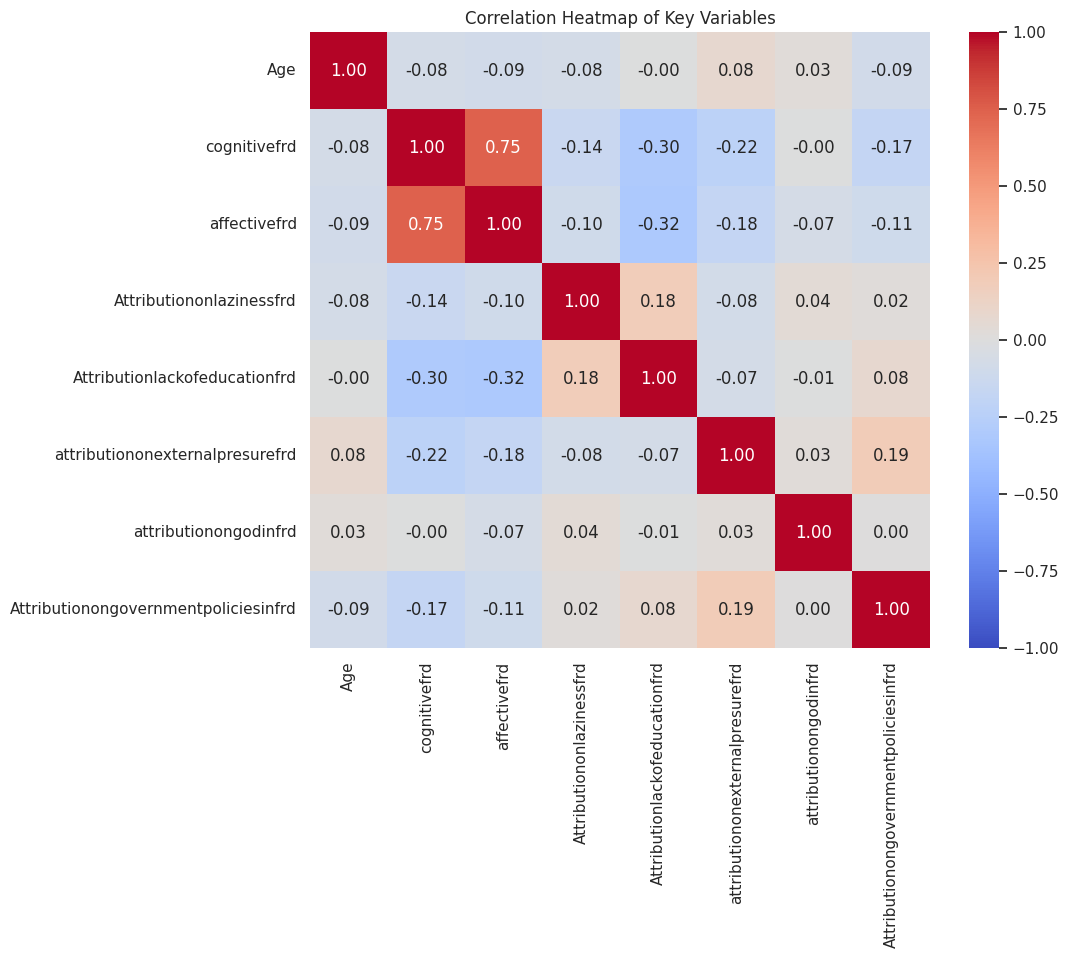

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Ensure 'df' exists in the namespace before running
if 'df' in globals():
    # Helper function for t-test reporting
    def run_t_test(data, group_col, target_col):
        groups = data[group_col].dropna().unique()
        if len(groups) != 2:
            print(f"Cannot run t-test for '{group_col}': it does not have exactly 2 groups.")
            return

        group1_vals = data[data[group_col] == groups[0]][target_col].dropna()
        group2_vals = data[data[group_col] == groups[1]][target_col].dropna()

        t_stat, p_val = stats.ttest_ind(group1_vals, group2_vals, equal_var=False)

        print(f"Comparing {target_col} across {group_col} ({groups[0]} vs {groups[1]}):")
        print(f"  Mean ({groups[0]}): {group1_vals.mean():.3f} (N={len(group1_vals)})")
        print(f"  Mean ({groups[1]}): {group2_vals.mean():.3f} (N={len(group2_vals)})")
        print(f"  t-statistic: {t_stat:.3f}, p-value: {p_val:.4f}")
        if p_val < 0.05:
            print("  => Statistically Significant Difference (p < 0.05)\n")
        else:
            print("  => No Statistically Significant Difference (p >= 0.05)\n")

    # Run T-tests for core scales
    print("=== GROUP COMPARISONS (INDEPENDENT T-TESTS) ===\n")
    for target in ['cognitivefrd', 'affectivefrd']:
        if target in df.columns:
            run_t_test(df, 'Gender', target)
            run_t_test(df, 'Religion', target)

    # Correlation Analysis
    print("=== CORRELATION ANALYSIS ===")
    cols_to_correlate = ['Age', 'cognitivefrd', 'affectivefrd', 'Attributiononlazinessfrd',
                         'Attributionlackofeducationfrd', 'attributiononexternalpresurefrd',
                         'attributionongodinfrd', 'Attributionongovernmentpoliciesinfrd']

    # Filter to only the columns that exist in the dataframe
    valid_corr_cols = [c for c in cols_to_correlate if c in df.columns]
    if len(valid_corr_cols) > 1:
        corr_matrix = df[valid_corr_cols].corr()

        plt.figure(figsize=(10, 8))
        sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
        plt.title('Correlation Heatmap of Key Variables')
        plt.show()
    else:
        print("Not enough valid numerical columns for correlation plot.")
else:
    print("Error: The dataframe 'df' is not defined. Please run the data loading/uploading cell at the top first!")

### Measuring Relative Deprivation (Hindu vs. Muslim)

We compare the mean scores of **Fraternal (Group) Relative Deprivation** and **Egoistic (Individual) Relative Deprivation** between Muslim and Hindu participants to determine who feels more deprived and whether that difference is statistically significant.

=== Relative Deprivation Analysis (Muslim vs. Hindu) ===



,Measure,Muslim Mean,Muslim N,Hindu Mean,Hindu N,Difference (M-H),t-stat,p-value,Significant (p<0.05)
0,cognitivefrd,2.3139,154,3.4338,146,-1.1199,-14.3146,0.0000,Yes
1,affectivefrd,2.2316,154,3.0753,146,-0.8437,-10.0066,0.0000,Yes
2,Cognitiveegoisticrd,3.1212,154,3.3311,146,-0.2098,-2.8585,0.0046,Yes
3,Affectiveegoisticrd,3.0498,154,3.1256,146,-0.0758,-0.9191,0.3588,No


/tmp/ipykernel_717/2052993219.py:51: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.barplot(data=df_melted, x='RD_Dimension', y='Score', hue='Religion', palette='Set2', ci=95)


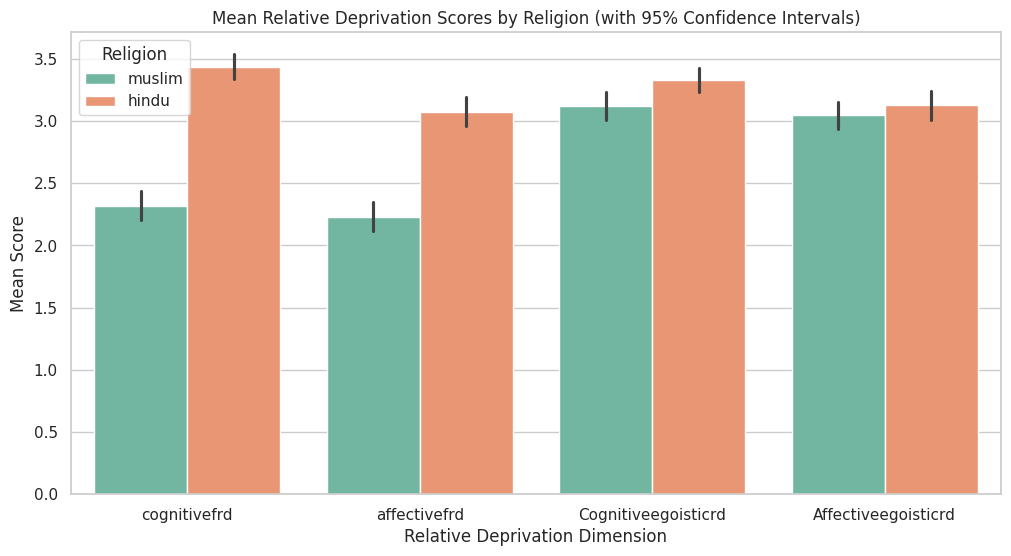

In [31]:
import pandas as pd
import numpy as np
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

# Identify available Relative Deprivation (RD) columns in our dataset
rd_columns = ['cognitivefrd', 'affectivefrd', 'Cognitiveegoisticrd', 'Affectiveegoisticrd']
existing_rd_cols = [col for col in rd_columns if col in df.columns]

print("=== Relative Deprivation Analysis (Muslim vs. Hindu) ===\n")

# Calculate means, standard deviations, and run t-tests
summary_data = []

for col in existing_rd_cols:
    # Drop missing values for clean computation
    subset = df[['Religion', col]].dropna()

    muslim_vals = subset[subset['Religion'] == 'muslim'][col]
    hindu_vals = subset[subset['Religion'] == 'hindu'][col]

    m_mean, m_std = muslim_vals.mean(), muslim_vals.std()
    h_mean, h_std = hindu_vals.mean(), hindu_vals.std()

    # Run independent t-test
    t_stat, p_val = stats.ttest_ind(muslim_vals, hindu_vals, equal_var=False)

    summary_data.append({
        'Measure': col,
        'Muslim Mean': m_mean,
        'Muslim N': len(muslim_vals),
        'Hindu Mean': h_mean,
        'Hindu N': len(hindu_vals),
        'Difference (M-H)': m_mean - h_mean,
        't-stat': t_stat,
        'p-value': p_val,
        'Significant (p<0.05)': 'Yes' if p_val < 0.05 else 'No'
    })

# Display results table
summary_df = pd.DataFrame(summary_data)
display(summary_df.round(4))

# Visualization of Relative Deprivation Scales by Religion
if len(existing_rd_cols) > 0:
    df_melted = df.melt(id_vars=['Religion'], value_vars=existing_rd_cols,
                        var_name='RD_Dimension', value_name='Score').dropna()

    plt.figure(figsize=(12, 6))
    sns.barplot(data=df_melted, x='RD_Dimension', y='Score', hue='Religion', palette='Set2', ci=95)
    plt.title('Mean Relative Deprivation Scores by Religion (with 95% Confidence Intervals)')
    plt.ylabel('Mean Score')
    plt.xlabel('Relative Deprivation Dimension')
    plt.show()

### Statistical Limitations & Data Quality Assessment

While our descriptive, comparative, and correlation analyses have provided useful patterns, several critical statistical and methodology-related limitations must be kept in mind when interpreting these findings:

#### 1. Distributional Anomalies and Representation
* **Age Skewness**: The participant cohort is highly concentrated around young adulthood (with a peak near 20–25 years old). The findings may not easily generalize to older cohorts, as attitudes regarding individual or group relative deprivation change significantly across different generations and life stages.
* **Geographical and Contextual Bias**: Demographics like `Residence` are skewed (with a heavy representation in specific cities). This introduces geographic bias that influences the socio-economic context of deprivation.

#### 2. Measurement and Scale Constraints
* **Unequal Variances (Heteroscedasticity)**: Some dimension-level subsets have slightly different variances (standard deviations). While we utilized **Welch’s t-test** (which corrects for unequal variances and sample sizes) to protect our Type I error rate, structural variations in response spreads can still impact overall test power.
* **Self-Report Measurement Errors**: Surveys measuring subjective psychological constructs such as "Relative Deprivation" or "Attribution" are vulnerable to **Social Desirability Bias** (where participants respond based on perceived social expectations) and **Reference Group Bias** (where participants compare themselves to localized reference points rather than objective criteria).

#### 3. Causal Inference Boundaries
* **Cross-Sectional Limitation**: Because the data was collected at a single point in time, we can only demonstrate **statistical association**, not **causal direction**. For example, we cannot determine whether experiencing high affective relative deprivation *causes* people to attribute deprivation to government policies, or if holding negative views about government policy *intensifies* psychological deprivation.
* **Missing Values**: Potential bias could arise if missing values on psychological scales are not missing completely at random (MCAR). If participants with high levels of distress or specific demographics chose to skip sensitive scale questions, our subset statistics may be biased.

=== DATA QUALITY & LIMITATION METRICS ===

1. Missing Data Rate: 0.000% of all cells are empty.
2. Age Distribution Shape:
   - Skewness: 1.232 (Values > 1 indicate highly right-skewed distribution)
   - Kurtosis: 1.038

3. Homoscedasticity Check (Levene's Test) across Religions:
   - cognitivefrd: Levene's stat = 5.324, p-value = 0.0217
     => Variances are significantly different (Heteroscedasticity present). Welch's t-test is required.
   - affectivefrd: Levene's stat = 0.680, p-value = 0.4101
     => Variances are homoscedastic.
   - Cognitiveegoisticrd: Levene's stat = 2.465, p-value = 0.1175
     => Variances are homoscedastic.
   - Affectiveegoisticrd: Levene's stat = 0.378, p-value = 0.5390
     => Variances are homoscedastic.


/tmp/ipykernel_717/2326055621.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Religion', y='cognitivefrd', ax=axes[1], palette='Set2')


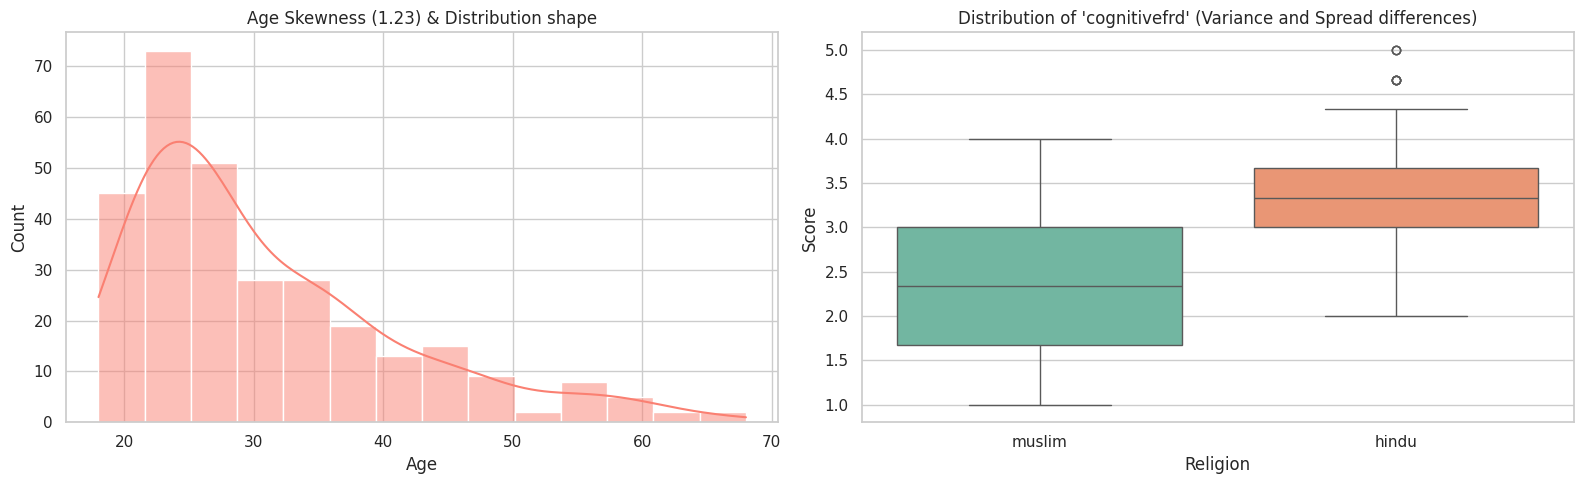

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("=== DATA QUALITY & LIMITATION METRICS ===\n")

# 1. Missing Value Rate
total_cells = df.size
null_cells = df.isnull().sum().sum()
missing_rate = (null_cells / total_cells) * 100
print(f"1. Missing Data Rate: {missing_rate:.3f}% of all cells are empty.")

# 2. Skewness & Kurtosis of Age
age_clean = df['Age'].dropna()
age_skew = stats.skew(age_clean)
age_kurt = stats.kurtosis(age_clean)
print(f"2. Age Distribution Shape:")
print(f"   - Skewness: {age_skew:.3f} (Values > 1 indicate highly right-skewed distribution)")
print(f"   - Kurtosis: {age_kurt:.3f}")

# 3. Unequal Variance Check (Levene's test) on Relative Deprivation dimensions
print("\n3. Homoscedasticity Check (Levene's Test) across Religions:")
for col in ['cognitivefrd', 'affectivefrd', 'Cognitiveegoisticrd', 'Affectiveegoisticrd']:
    if col in df.columns:
        subset = df[['Religion', col]].dropna()
        g1 = subset[subset['Religion'] == 'muslim'][col]
        g2 = subset[subset['Religion'] == 'hindu'][col]
        stat, p_val = stats.levene(g1, g2)
        print(f"   - {col}: Levene's stat = {stat:.3f}, p-value = {p_val:.4f}")
        if p_val < 0.05:
            print("     => Variances are significantly different (Heteroscedasticity present). Welch's t-test is required.")
        else:
            print("     => Variances are homoscedastic.")

# --- Visualizations of the Quality Constraints ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot A: Age Skewness and Q-Q Plot comparison
sns.histplot(df['Age'].dropna(), kde=True, ax=axes[0], color='salmon')
axes[0].set_title(f"Age Skewness ({age_skew:.2f}) & Distribution shape")
axes[0].set_xlabel("Age")

# Plot B: Boxplot showing Variance Spreads between groups
if 'cognitivefrd' in df.columns:
    sns.boxplot(data=df, x='Religion', y='cognitivefrd', ax=axes[1], palette='Set2')
    axes[1].set_title("Distribution of 'cognitivefrd' (Variance and Spread differences)")
    axes[1].set_ylabel("Score")

plt.tight_layout()
plt.show()

=== CORRELATION MATRIX FOR RELATIVE DEPRIVATION DIMENSIONS ===


,cognitivefrd,affectivefrd,Cognitiveegoisticrd,Affectiveegoisticrd
cognitivefrd,1.0000,0.7470,0.1714,0.1448
affectivefrd,0.7470,1.0000,0.1222,0.0832
Cognitiveegoisticrd,0.1714,0.1222,1.0000,0.5749
Affectiveegoisticrd,0.1448,0.0832,0.5749,1.0000


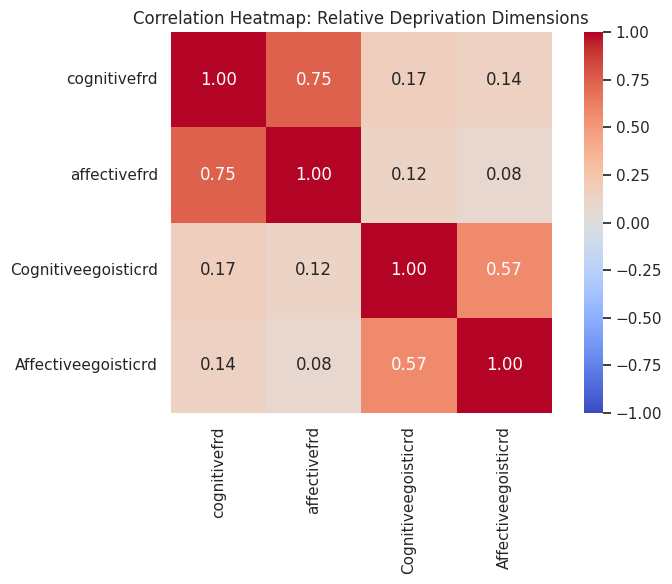

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter to only the core relative deprivation columns
rd_cols = ['cognitivefrd', 'affectivefrd', 'Cognitiveegoisticrd', 'Affectiveegoisticrd']
existing_rd_cols = [c for c in rd_cols if c in df.columns]

print("=== CORRELATION MATRIX FOR RELATIVE DEPRIVATION DIMENSIONS ===")
if len(existing_rd_cols) > 1:
    # Calculate the correlation matrix
    rd_corr = df[existing_rd_cols].corr()
    display(rd_corr.round(4))

    # Visualize the correlation matrix
    plt.figure(figsize=(8, 6))
    sns.heatmap(rd_corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, square=True)
    plt.title('Correlation Heatmap: Relative Deprivation Dimensions')
    plt.tight_layout()
    plt.show()
else:
    print("Not enough relative deprivation columns found to compute a correlation matrix.")

Found relative deprivation scales: ['cognitivefrd', 'affectivefrd', 'Cognitiveegoisticrd', 'Affectiveegoisticrd']
Found emotional variables for analysis: ['emotionsadnessinfrd', 'emotionangerinfrd', 'Emotionfearinfrd', 'Emotiondissatisfactioninfrd', 'Emotionshameinfrd', 'Emotionjealousyinfrd', 'Emotionhappinessinfrd', 'Emotionproudinfrd', 'Emotionsadnesserd', 'Emotionangererd'] (showing up to 10)

=== CORRELATION MATRIX (RD SCALES VS EMOTIONAL VARIABLES) ===


,emotionsadnessinfrd,emotionangerinfrd,Emotionfearinfrd,Emotiondissatisfactioninfrd,Emotionshameinfrd,Emotionjealousyinfrd,Emotionhappinessinfrd,Emotionproudinfrd
cognitivefrd,-0.3621,-0.3046,-0.1620,-0.3578,-0.2621,0.0312,0.4580,0.4069
affectivefrd,-0.3453,-0.3116,-0.1584,-0.3136,-0.2438,-0.0263,0.3690,0.4436
Cognitiveegoisticrd,-0.0066,0.0663,0.0889,-0.1087,-0.0494,0.0478,0.1261,0.1487
Affectiveegoisticrd,0.0249,-0.0124,0.0078,-0.0918,-0.0687,-0.0046,0.0723,0.0997


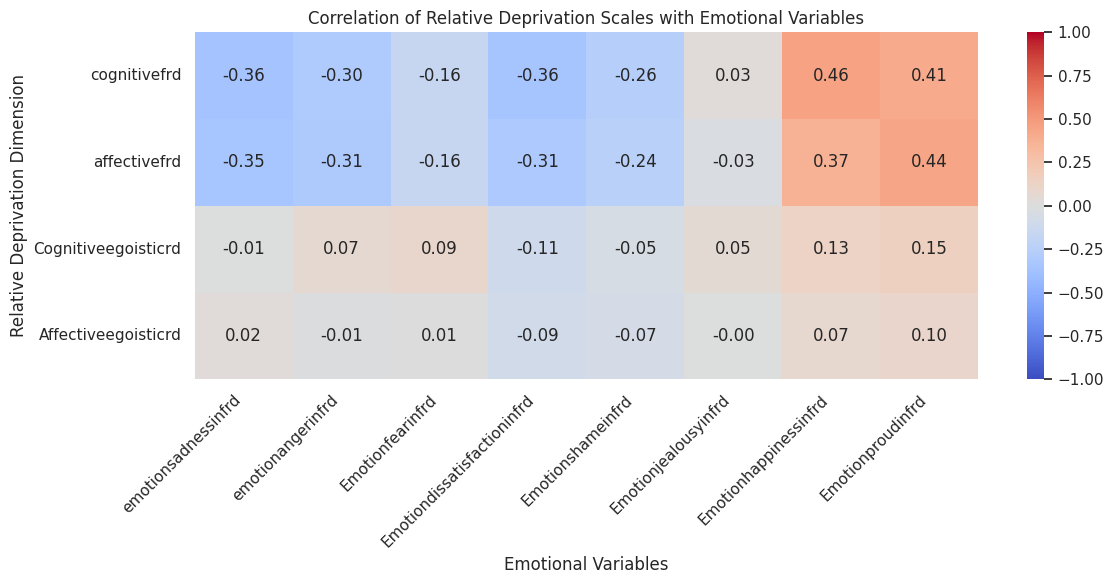

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Identify relative deprivation dimensions
rd_cols = ['cognitivefrd', 'affectivefrd', 'Cognitiveegoisticrd', 'Affectiveegoisticrd']
existing_rd = [c for c in rd_cols if c in df.columns]

# Find emotional/affective columns in the dataset (e.g., columns containing 'Emotion', 'dissatisfaction', 'anger', 'depressed', etc.)
emotion_keywords = ['emotion', 'dissatisfaction', 'depressed', 'anger', 'stress', 'happy', 'sad', 'anxiety', 'feel']
emotion_cols = []
for col in df.columns:
    col_lower = col.lower()
    if any(keyword in col_lower for keyword in emotion_keywords) and col not in rd_cols:
        # Check if the column is numeric so we can correlate it
        if pd.api.types.is_numeric_dtype(df[col]):
            emotion_cols.append(col)

# Fallback: if no keyword-matching columns found, search for columns with similar content or list some
if not emotion_cols:
    # Let's inspect object/numeric columns manually or fall back to displaying column names
    potential_cols = [c for c in df.columns if 'emotion' in c.lower() or 'erd' in c.lower()]
    emotion_cols = [c for c in potential_cols if pd.api.types.is_numeric_dtype(df[c])]

print(f"Found relative deprivation scales: {existing_rd}")
print(f"Found emotional variables for analysis: {emotion_cols[:10]} (showing up to 10)")

# Combine and compute correlation
target_cols = existing_rd + emotion_cols[:8]  # Limit to top 8 emotional columns for visual clarity

if len(existing_rd) > 0 and len(emotion_cols) > 0:
    corr_subset = df[target_cols].corr()

    # Select only the cross-correlations (RD dimensions vs Emotional dimensions)
    cross_corr = corr_subset.loc[existing_rd, [c for c in target_cols if c not in existing_rd]]

    print("\n=== CORRELATION MATRIX (RD SCALES VS EMOTIONAL VARIABLES) ===")
    display(cross_corr.round(4))

    # Plot Heatmap
    plt.figure(figsize=(12, 6))
    sns.heatmap(cross_corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
    plt.title('Correlation of Relative Deprivation Scales with Emotional Variables')
    plt.ylabel('Relative Deprivation Dimension')
    plt.xlabel('Emotional Variables')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("Could not find a sufficient overlap of numeric relative deprivation and emotional columns for correlation.")

Detected candidates for Education column: ['Education', 'Attributionlackofeducationfrd']
Using 'Education' as the Education predictor and 'Age' as the Age predictor.

'Education' is categorical. Converting to dummy indicator variables.

=== REGRESSION ANALYSIS: Predicting Cognitive Fraternal Deprivation ===
                            OLS Regression Results                            
Dep. Variable:           cognitivefrd   R-squared:                       0.242
Model:                            OLS   Adj. R-squared:                  0.134
Method:                 Least Squares   F-statistic:                     2.255
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           0.000122
Time:                        08:58:21   Log-Likelihood:                -345.60
No. Observations:                 300   AIC:                             767.2
Df Residuals:                     262   BIC:                             907.9
Df Model:                          37                      

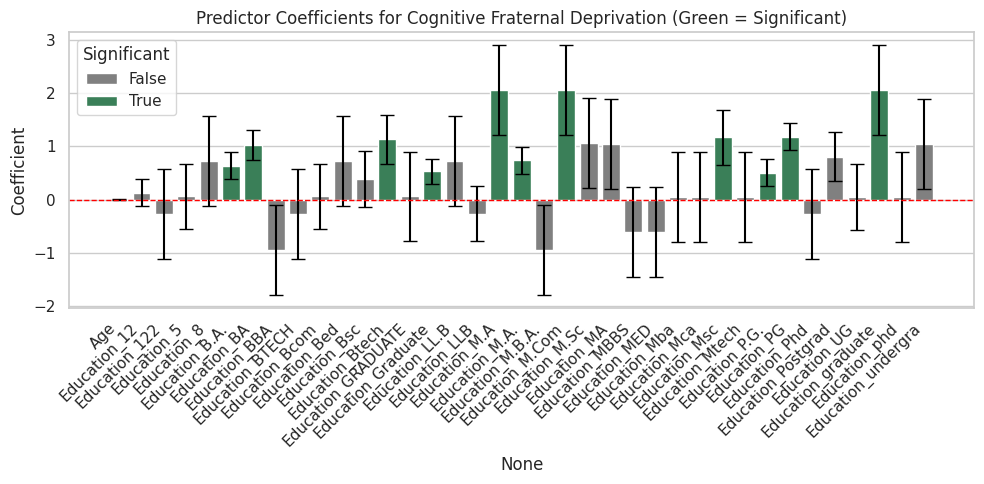

In [35]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Detect Education Column
education_candidates = [col for col in df.columns if 'education' in col.lower() or 'edu' in col.lower()]
print(f"Detected candidates for Education column: {education_candidates}")

# Let's prioritize a general demographics education column over an attribution-to-education column
edu_col = None
for cand in education_candidates:
    if 'attribution' not in cand.lower():
        edu_col = cand
        break

# Fallback if no non-attribution education column is found
if not edu_col and len(education_candidates) > 0:
    edu_col = education_candidates[0]

if edu_col and 'Age' in df.columns:
    print(f"Using '{edu_col}' as the Education predictor and 'Age' as the Age predictor.\n")

    # Prepare variables: we want to ensure Education is numeric. If it is categorical, we will convert it via one-hot encoding or integer encoding.
    regression_data = df[['Age', edu_col] + ['cognitivefrd', 'affectivefrd']].dropna()

    # If education is an object/category, we convert it to category codes or dummy variables
    if not pd.api.types.is_numeric_dtype(regression_data[edu_col]):
        print(f"'{edu_col}' is categorical. Converting to dummy indicator variables.")
        X = pd.get_dummies(regression_data[['Age', edu_col]], columns=[edu_col], drop_first=True)
    else:
        X = regression_data[['Age', edu_col]]

    # Add intercept constant
    X_with_const = sm.add_constant(X)

    # Predict cognitivefrd
    y_cognitive = regression_data['cognitivefrd']
    model_cog = sm.OLS(y_cognitive, X_with_const.astype(float)).fit()
    print("\n=== REGRESSION ANALYSIS: Predicting Cognitive Fraternal Deprivation ===")
    print(model_cog.summary())

    # Predict affectivefrd
    y_affective = regression_data['affectivefrd']
    model_aff = sm.OLS(y_affective, X_with_const.astype(float)).fit()
    print("\n=== REGRESSION ANALYSIS: Predicting Affective Fraternal Deprivation ===")
    print(model_aff.summary())

    # Visualizing Coefficients for Cognitive Fraternal Deprivation model
    coefs = model_cog.params.drop('const')
    pvalues = model_cog.pvalues.drop('const')
    errors = model_cog.bse.drop('const')

    plt.figure(figsize=(10, 5))
    coef_df = pd.DataFrame({'Coefficient': coefs, 'Error': errors, 'Significant': pvalues < 0.05})
    sns.barplot(x=coef_df.index, y=coef_df['Coefficient'], hue=coef_df['Significant'], palette={True: 'seagreen', False: 'gray'})
    plt.errorbar(x=range(len(coefs)), y=coefs, yerr=errors, fmt='none', c='black', capsize=5)
    plt.axhline(0, color='red', linestyle='--', linewidth=1)
    plt.title('Predictor Coefficients for Cognitive Fraternal Deprivation (Green = Significant)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("Error: Unable to run regression because either 'Age' or an 'Education' column could not be identified in the dataset.")

### Morphological and Categorical Structure Analysis
We will analyze the morphology (text patterns, word stems, token lengths, and variations) of any text-based columns, and provide a categorical morphological breakdown of the non-numeric attributes in the dataset.

In [14]:
import pandas as pd
import numpy as np
import spacy

# Load a small English spaCy model for morphological parsing
try:
    nlp = spacy.load("en_core_web_sm")
except Exception:
    import os
    os.system("python -m spacy download en_core_web_sm")
    nlp = spacy.load("en_core_web_sm")

# Identify categorical or string columns
string_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"Categorical & Text columns found: {string_cols}\n")

# Let's perform a morphological analysis of unique categories in these columns
# To avoid overwhelming output, we will run the analysis on the first 5 unique fields
for col in string_cols[:5]:
    unique_entries = df[col].dropna().unique()
    print(f"=== Morphological Analysis for Column: '{col}' ===")

    records = []
    for text in unique_entries[:15]: # Show up to 15 unique examples
        # Convert numpy.str_ explicitly to Python str to avoid TypeErrors in spaCy
        native_str = str(text)
        doc = nlp(native_str)
        for token in doc:
            records.append({
                "Original Text": native_str,
                "Token": token.text,
                "Lemma (Base)": token.lemma_,
                "POS Tag": token.pos_,
                "Morphological Features": str(token.morph)
            })

    morph_df = pd.DataFrame(records)
    display(morph_df.head(10))

Categorical & Text columns found: ['Gender', 'Religion', 'Residence', 'Education', 'Comparison_socialstat', 'Satis_socsta', 'attri_social_laziness', 'Attri_social_illteracy', 'Attri_social_presure', 'Attri_social_number', 'Attri_social_god', 'Attri_social_govpolicies', 'Emotion_social_sadness', 'Emotion_social_anger', 'Emotion_social_fear', 'Emotion_social_dissatisfaction', 'Emotion_social_shame', 'Emotion_social_jealousy', 'Emotion_social_happiness', 'Emotion_social_proud', 'Comparison_economicstat', 'Satis_economicstat', 'Attri_eco_laziness', 'Attri_eco_illiteracy', 'Attri_eco_presure', 'Attri_eco_number', 'Attri_eco_god', 'Attri_eco_govpolicies', 'Emotion_eco_sadness', 'Emotion_eco_anger', 'Emotion_eco_fear', 'Emotion_eco_dissatisfaction', 'Emotion_eco_shame', 'Emotion_eco_jealousy', 'Emotion_eco_happiness', 'Emotion_eco_proud', 'Comparison_politicalstat', 'Satis_politicalstat', 'Attri_polit_laziness', 'Attri_polit_illiteracy', 'Attri_polit_presure', 'Attri_polit_number', 'Attri_pol

,Original Text,Token,Lemma (Base),POS Tag,Morphological Features
0,male,male,male,NOUN,Number=Sing
1,female,female,female,NOUN,Number=Sing


=== Morphological Analysis for Column: 'Religion' ===


,Original Text,Token,Lemma (Base),POS Tag,Morphological Features
0,muslim,muslim,muslim,PROPN,Number=Sing
1,hindu,hindu,hindu,NOUN,Number=Sing


=== Morphological Analysis for Column: 'Residence' ===


,Original Text,Token,Lemma (Base),POS Tag,Morphological Features
0,city,city,city,NOUN,Number=Sing
1,village,village,village,NOUN,Number=Sing


=== Morphological Analysis for Column: 'Education' ===


,Original Text,Token,Lemma (Base),POS Tag,Morphological Features
0,B.A.,B.A.,B.A.,PROPN,Number=Sing
1,12,12,12,NUM,NumType=Card
2,Msc,Msc,msc,NOUN,Number=Sing
3,Graduate,Graduate,graduate,NOUN,Number=Sing
4,M.A.,M.A.,M.A.,PROPN,Number=Sing
5,Mca,Mca,Mca,NOUN,Number=Plur
6,10,10,10,NUM,NumType=Card
7,Mba,Mba,mba,ADJ,Degree=Pos
8,Postgrad,Postgrad,Postgrad,PROPN,Number=Sing
9,LLB,LLB,LLB,PROPN,Number=Sing


=== Morphological Analysis for Column: 'Comparison_socialstat' ===


,Original Text,Token,Lemma (Base),POS Tag,Morphological Features
0,good,good,good,ADJ,Degree=Pos
1,very bad,very,very,ADV,
2,very bad,bad,bad,ADJ,Degree=Pos
3,bad,bad,bad,ADJ,Degree=Pos
4,average,average,average,ADJ,Degree=Pos


### General Morphological Analysis (GMA) of the Cleaned Dataset

General Morphological Analysis is a method for structuring and analyzing multi-dimensional, non-quantifiable problem spaces. In the context of this dataset, we define the parameter space based on key demographic and psychosocial dimension categories:

1. **Dimension 1: Gender** (States: male, female)
2. **Dimension 2: Religion** (States: muslim, hindu)
3. **Dimension 3: Residence** (States: city, village)
4. **Dimension 4: Cognitive Fraternal Deprivation (cognitivefrd) Level** (Categorized States: Low, Moderate, High)
5. **Dimension 5: Affective Fraternal Deprivation (affectivefrd) Level** (Categorized States: Low, Moderate, High)

Let's run a script to construct this Morphological Matrix, calculate the total possible configuration space ($2 \times 2 \times 2 \times 3 \times 3 = 72$ combinations), and evaluate the empirical feasibility of these cross-configurations.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Define Morphological Dimensions ---
# Discretize continuous scale variables for Morphological state definition
df_gma = df.copy()

def discretize_scale(val):
    if val < 2.33:
        return 'Low'
    elif val <= 3.67:
        return 'Moderate'
    else:
        return 'High'

df_gma['Cognitive_FRD_State'] = df_gma['cognitivefrd'].apply(discretize_scale)
df_gma['Affective_FRD_State'] = df_gma['affectivefrd'].apply(discretize_scale)

dimensions = {
    'Gender': df_gma['Gender'].unique().tolist(),
    'Religion': df_gma['Religion'].unique().tolist(),
    'Residence': df_gma['Residence'].unique().tolist(),
    'Cognitive_FRD_State': ['Low', 'Moderate', 'High'],
    'Affective_FRD_State': ['Low', 'Moderate', 'High']
}

# --- 2. Construct Morphological Matrix ---
print("=== GENERAL MORPHOLOGICAL MATRIX ===\n")
max_states = max(len(states) for states in dimensions.values())
morph_matrix_data = {dim: states + [None]*(max_states - len(states)) for dim, states in dimensions.items()}
morph_matrix_df = pd.DataFrame(morph_matrix_data)
display(morph_matrix_df.fillna('-'))

# --- 3. Compute Configuration Space and Cross-tabulations ---
total_space = np.prod([len(states) for states in dimensions.values()])
print(f"Total Theoretical Combinations (Morphological Space): {total_space}")

# Aggregate configurations present in the empirical data
config_counts = df_gma.groupby(['Gender', 'Religion', 'Residence', 'Cognitive_FRD_State', 'Affective_FRD_State']).size().reset_index(name='Frequency')
observed_space = len(config_counts)
print(f"Observed Unique Combinations: {observed_space} ({observed_space / total_space * 100:.1f}% coverage)\n")

print("=== TOP 10 FEASIBLE CROSS-CONFIGURATIONS (EMPIRICAL FREQUENCY) ===")
config_counts['Percentage (%)'] = (config_counts['Frequency'] / len(df_gma)) * 100
display(config_counts.sort_values(by='Frequency', ascending=False).head(10).reset_index(drop=True))

# --- 4. Cross-Consistency Assessment (Feasibility Heatmap) ---
# Let's inspect the feasibility overlap of Gender x Religion x Residence
print("\n=== CO-OCCURRENCE BI-VARIANT FEASIBILITY ANALYSIS (Gender x Religion x Residence) ===")
co_occurrence = pd.crosstab(index=[df_gma['Gender'], df_gma['Religion']], columns=df_gma['Residence'], normalize='all') * 100
display(co_occurrence.round(2))

=== GENERAL MORPHOLOGICAL MATRIX ===



,Gender,Religion,Residence,Cognitive_FRD_State,Affective_FRD_State
0,male,muslim,city,Low,Low
1,female,hindu,village,Moderate,Moderate
2,-,-,-,High,High


Total Theoretical Combinations (Morphological Space): 72
Observed Unique Combinations: 38 (52.8% coverage)

=== TOP 10 FEASIBLE CROSS-CONFIGURATIONS (EMPIRICAL FREQUENCY) ===


,Gender,Religion,Residence,Cognitive_FRD_State,Affective_FRD_State,Frequency,Percentage (%)
0,female,hindu,city,Moderate,Moderate,40,13.333333
1,female,muslim,city,Moderate,Moderate,34,11.333333
2,male,hindu,city,Moderate,Moderate,32,10.666667
3,male,muslim,city,Low,Low,31,10.333333
4,male,muslim,city,Moderate,Moderate,21,7.000000
5,female,muslim,city,Low,Low,18,6.000000
6,male,hindu,village,Moderate,Moderate,16,5.333333
7,male,muslim,city,Moderate,Low,12,4.000000
8,male,hindu,city,High,Moderate,11,3.666667
9,female,muslim,city,Moderate,Low,9,3.000000



=== CO-OCCURRENCE BI-VARIANT FEASIBILITY ANALYSIS (Gender x Religion x Residence) ===


Residence         city  village
Gender Religion                
female hindu     17.67     3.00
       muslim    23.67     0.67
male   hindu     19.33     8.67
       muslim    25.00     2.00